Author: Malik Wensman

Email: mdwensma@ncsu.edu

Class: CSC 251-001 Fall 2026

Program: HW8

Purpose: practice in exploring data sets, merging data sets, performing simple and ## 6. Multiple Regression Analysis analysis, and utilizing models.

Bugs: None

Acknowledgements: None

Date: 10/17/2026

## 1. Project Setup and Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from mpl_toolkits.mplot3d import Axes3D
#scikit-learn

## 2. Data Import

In [2]:
j_df = pd.read_csv("Jaguar.csv")

j_df.head() 

,Unnamed: 0,Price,Age,Mileage
0,1,13.9,5,47.7
1,2,19.9,6,44.6
2,3,25.9,4,35.3
3,4,46.9,2,19.6
4,5,12.9,7,71.0


Removing the 1 indexed column

In [3]:
if "Unnamed: 0" in j_df.columns:
    j_df = j_df.drop(columns=["Unnamed: 0"])

j_df.head()

,Price,Age,Mileage
0,13.9,5,47.7
1,19.9,6,44.6
2,25.9,4,35.3
3,46.9,2,19.6
4,12.9,7,71.0


In [4]:
p_df = pd.read_csv("Porsche.csv")

p_df.head()

,Unnamed: 0,Price,Age,Mileage
0,1,69.4,3,21.5
1,2,56.9,3,43.0
2,3,49.9,2,19.9
3,4,47.4,4,36.0
4,5,42.9,4,44.0


Removing the 1 indexed column

In [5]:
if "Unnamed: 0" in p_df.columns:
    p_df = p_df.drop(columns=["Unnamed: 0"])

p_df.head()

,Price,Age,Mileage
0,69.4,3,21.5
1,56.9,3,43.0
2,49.9,2,19.9
3,47.4,4,36.0
4,42.9,4,44.0


Looking at their shape, both are 30 rows, 3 columns

In [6]:
print("\nPorsche Shape:", p_df.shape)
print("\nJaguar Shape:", j_df.shape)


Porsche Shape: (30, 3)

Jaguar Shape: (30, 3)


## 3. Data Preparation and Merging

In [7]:
j_df["Brand"] = "Jaguar"
p_df["Brand"] = "Porsche"

In [8]:
df = pd.concat([j_df, p_df], axis=0, ignore_index=True)
# Be sure to ignore the index when concatenating, 
# otherwise you will have duplicate indices in the new dataframe.
df.head()

,Price,Age,Mileage,Brand
0,13.9,5,47.7,Jaguar
1,19.9,6,44.6,Jaguar
2,25.9,4,35.3,Jaguar
3,46.9,2,19.6,Jaguar
4,12.9,7,71.0,Jaguar


In [9]:
df.tail()

,Price,Age,Mileage,Brand
55,33.9,7,50.4,Porsche
56,23.9,20,89.6,Porsche
57,22.9,22,83.4,Porsche
58,16.0,20,86.0,Porsche
59,52.9,3,37.4,Porsche


Make Brand a categorical variable so we can group by it

In [10]:
df["Brand"] = df["Brand"].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   Price    60 non-null     float64 
 1   Age      60 non-null     int64   
 2   Mileage  60 non-null     float64 
 3   Brand    60 non-null     category
dtypes: category(1), float64(2), int64(1)
memory usage: 1.6 KB


The price is given in units of thousands of US dollars, age is given in years, and mileage is given in thousands of miles

Checking if there are any missing values

In [11]:
Nan_count = df.isnull().sum()
print(Nan_count)

Price      0
Age        0
Mileage    0
Brand      0
dtype: int64


### 4.4 Key EDA Findings

The age and mileage relationships both look roughly linear, with price generally decreasing as age or mileage increases. The combined data is useful for a pooled overview, but brand-specific plots still show whether Jaguar and Porsche follow similar patterns.

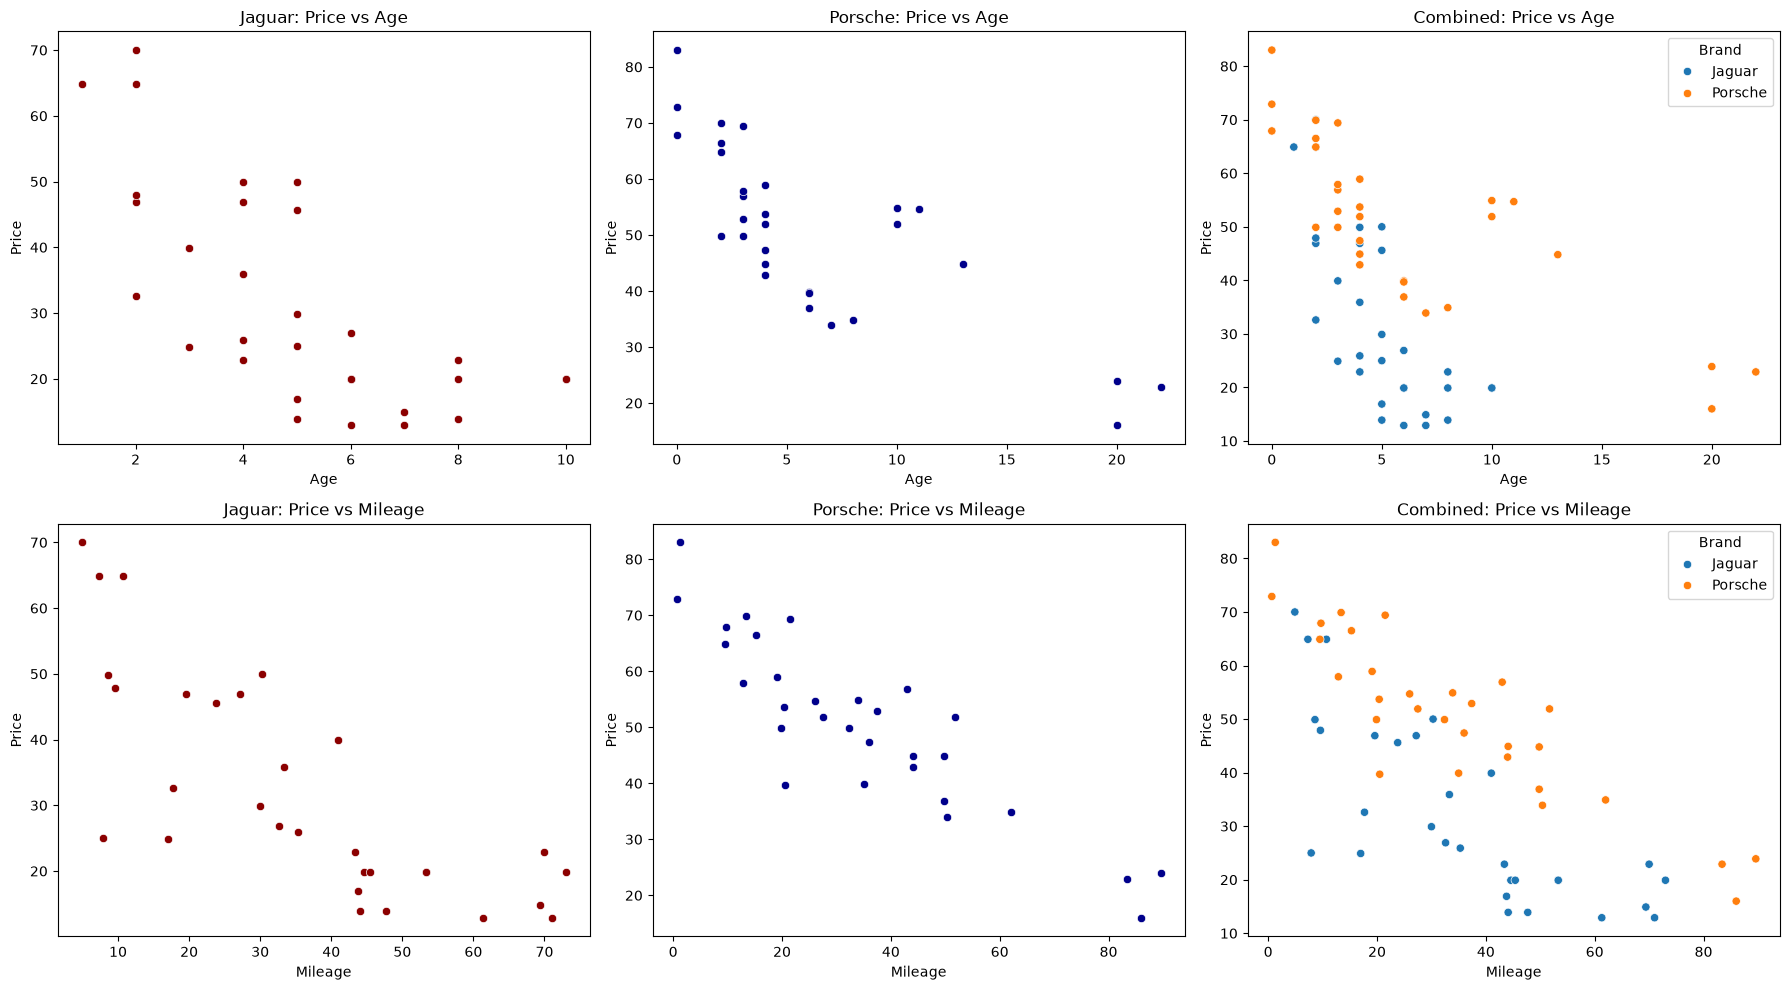

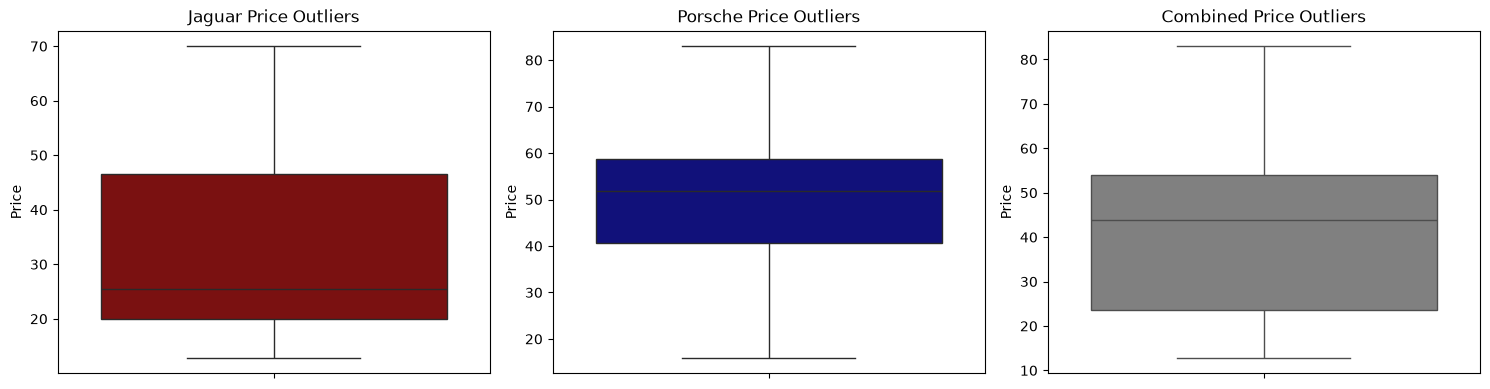

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.scatterplot(data=j_df, x="Age", y="Price", ax=axes[0, 0], color="darkred")
axes[0, 0].set_title("Jaguar: Price vs Age")

sns.scatterplot(data=p_df, x="Age", y="Price", ax=axes[0, 1], color="darkblue")
axes[0, 1].set_title("Porsche: Price vs Age")

sns.scatterplot(data=df, x="Age", y="Price", hue="Brand", ax=axes[0, 2])
axes[0, 2].set_title("Combined: Price vs Age")

sns.scatterplot(data=j_df, x="Mileage", y="Price", ax=axes[1, 0], color="darkred")
axes[1, 0].set_title("Jaguar: Price vs Mileage")

sns.scatterplot(data=p_df, x="Mileage", y="Price", ax=axes[1, 1], color="darkblue")
axes[1, 1].set_title("Porsche: Price vs Mileage")

sns.scatterplot(data=df, x="Mileage", y="Price", hue="Brand", ax=axes[1, 2])
axes[1, 2].set_title("Combined: Price vs Mileage")

plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=j_df["Price"], ax=axes[0], color="darkred")
axes[0].set_title("Jaguar Price Outliers")
sns.boxplot(y=p_df["Price"], ax=axes[1], color="darkblue")
axes[1].set_title("Porsche Price Outliers")
sns.boxplot(y=df["Price"], ax=axes[2], color="gray")
axes[2].set_title("Combined Price Outliers")
plt.tight_layout()

### 4.5 Scatter Plots, Correlations, and Outliers

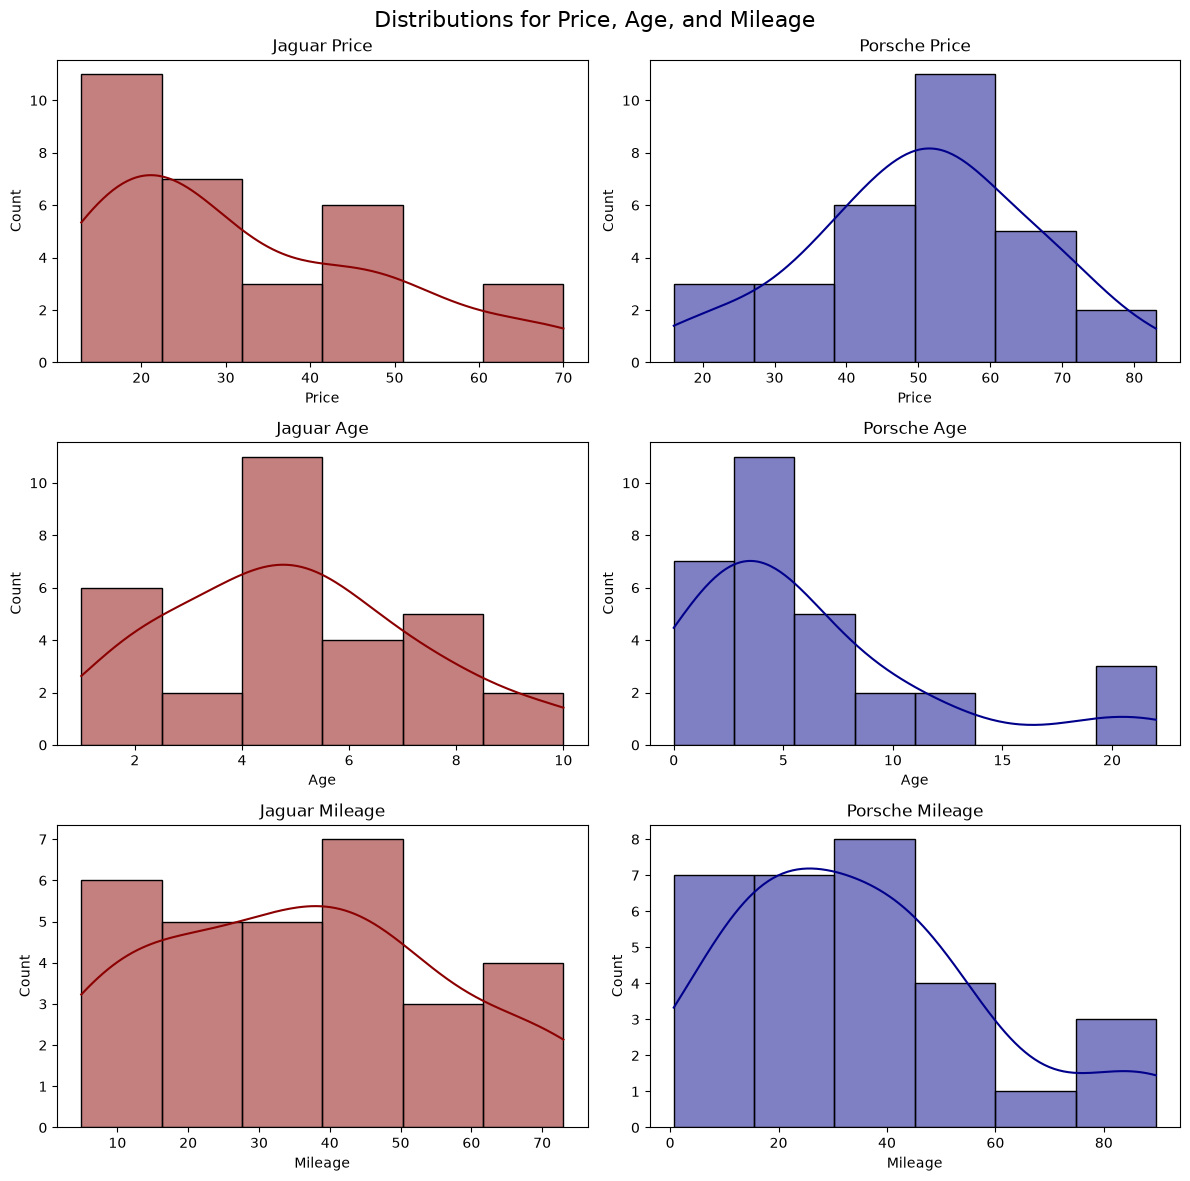

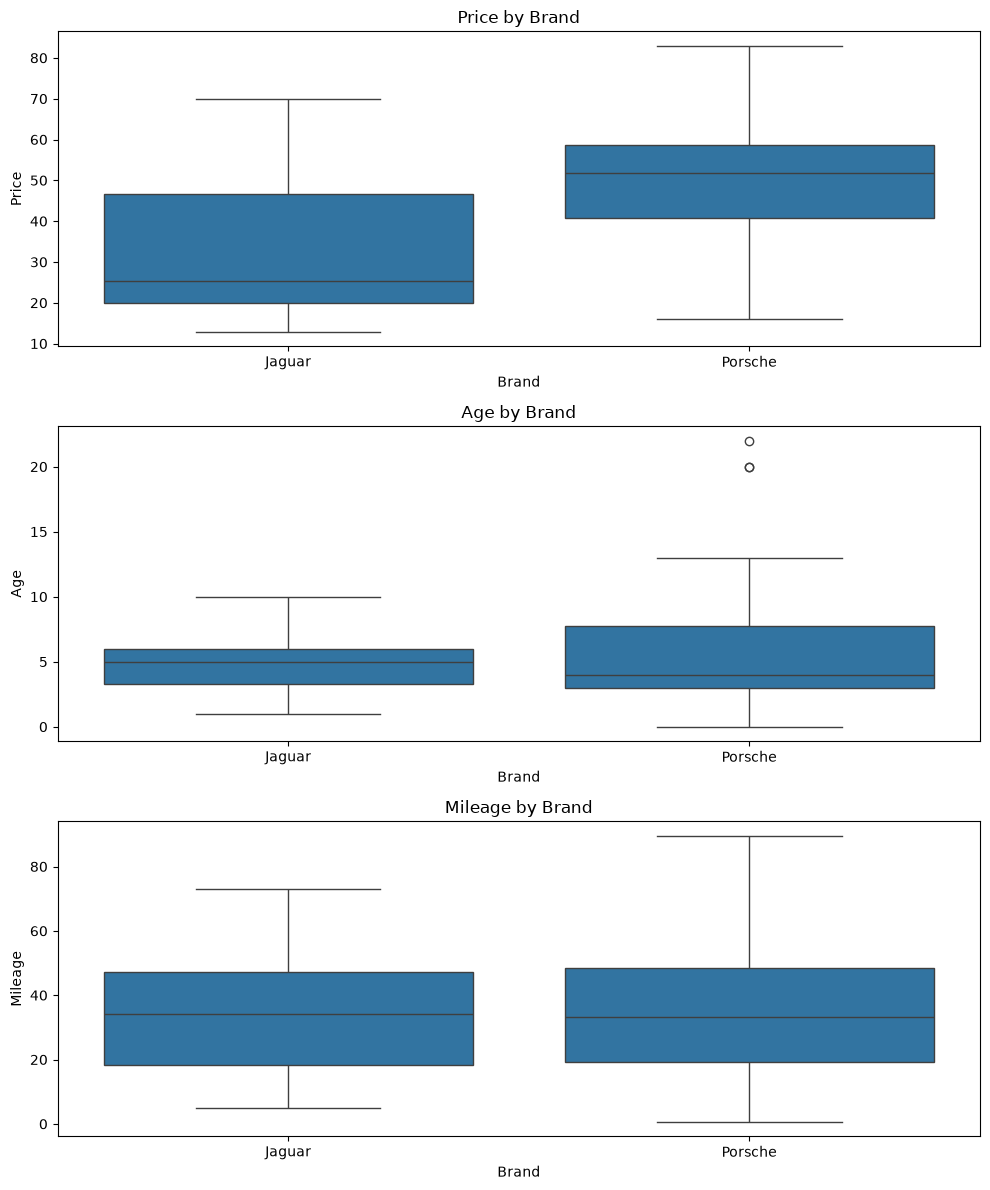

In [13]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
fig.suptitle("Distributions for Price, Age, and Mileage", fontsize=16)

sns.histplot(j_df["Price"], kde=True, ax=axes[0, 0], color="darkred")
axes[0, 0].set_title("Jaguar Price")
sns.histplot(p_df["Price"], kde=True, ax=axes[0, 1], color="darkblue")
axes[0, 1].set_title("Porsche Price")

sns.histplot(j_df["Age"], kde=True, ax=axes[1, 0], color="darkred")
axes[1, 0].set_title("Jaguar Age")
sns.histplot(p_df["Age"], kde=True, ax=axes[1, 1], color="darkblue")
axes[1, 1].set_title("Porsche Age")

sns.histplot(j_df["Mileage"], kde=True, ax=axes[2, 0], color="darkred")
axes[2, 0].set_title("Jaguar Mileage")
sns.histplot(p_df["Mileage"], kde=True, ax=axes[2, 1], color="darkblue")
axes[2, 1].set_title("Porsche Mileage")

plt.tight_layout()

fig, axes = plt.subplots(3, 1, figsize=(10, 12))
sns.boxplot(data=df, x="Brand", y="Price", ax=axes[0])
axes[0].set_title("Price by Brand")
sns.boxplot(data=df, x="Brand", y="Age", ax=axes[1])
axes[1].set_title("Age by Brand")
sns.boxplot(data=df, x="Brand", y="Mileage", ax=axes[2])
axes[2].set_title("Mileage by Brand")
plt.tight_layout()

### 4.6 Distribution Checks and Brand Comparison

In [14]:
print("Jaguar descriptive stats:\n", j_df.describe())
print("\nPorsche descriptive stats:\n", p_df.describe())
print("\nCombined descriptive stats:\n", df.describe())

Jaguar descriptive stats:
            Price        Age    Mileage
count  30.000000  30.000000  30.000000
mean   31.956667   4.966667  35.903333
std    16.797900   2.370557  20.808362
min    12.900000   1.000000   4.900000
25%    19.900000   3.250000  18.175000
50%    25.450000   5.000000  34.300000
75%    46.575000   6.000000  47.125000
max    70.000000  10.000000  73.000000

Porsche descriptive stats:
            Price        Age    Mileage
count  30.000000  30.000000  30.000000
mean   50.536667   6.200000  34.872333
std    15.542211   5.868678  23.504416
min    16.000000   0.000000   0.670000
25%    40.650000   3.000000  19.300000
50%    51.900000   4.000000  33.150000
75%    58.650000   7.750000  48.375000
max    83.000000  22.000000  89.600000

Combined descriptive stats:
            Price        Age    Mileage
count  60.000000  60.000000  60.000000
mean   41.246667   5.583333  35.387833
std    18.579380   4.480813  22.014581
min    12.900000   0.000000   0.670000
25%    23.650000 

In [15]:
print("Jaguar shape:", j_df.shape)
print("Porsche shape:", p_df.shape)
print("Combined shape:", df.shape)

print("\nJaguar columns:", j_df.columns.tolist())
print("Porsche columns:", p_df.columns.tolist())
print("Combined columns:", df.columns.tolist())

print("\nJaguar dtypes:\n", j_df.dtypes)
print("\nPorsche dtypes:\n", p_df.dtypes)
print("\nCombined dtypes:\n", df.dtypes)

print("\nJaguar missing values:\n", j_df.isna().sum())
print("\nPorsche missing values:\n", p_df.isna().sum())
print("\nCombined missing values:\n", df.isna().sum())

Jaguar shape: (30, 4)
Porsche shape: (30, 4)
Combined shape: (60, 4)

Jaguar columns: ['Price', 'Age', 'Mileage', 'Brand']
Porsche columns: ['Price', 'Age', 'Mileage', 'Brand']
Combined columns: ['Price', 'Age', 'Mileage', 'Brand']

Jaguar dtypes:
 Price      float64
Age          int64
Mileage    float64
Brand          str
dtype: object

Porsche dtypes:
 Price      float64
Age          int64
Mileage    float64
Brand          str
dtype: object

Combined dtypes:
 Price       float64
Age           int64
Mileage     float64
Brand      category
dtype: object

Jaguar missing values:
 Price      0
Age        0
Mileage    0
Brand      0
dtype: int64

Porsche missing values:
 Price      0
Age        0
Mileage    0
Brand      0
dtype: int64

Combined missing values:
 Price      0
Age        0
Mileage    0
Brand      0
dtype: int64


## 4. Exploratory Data Analysis

### 4.1 Data Structure and Quality

### 4.2 Mileage vs Price Scatterplots

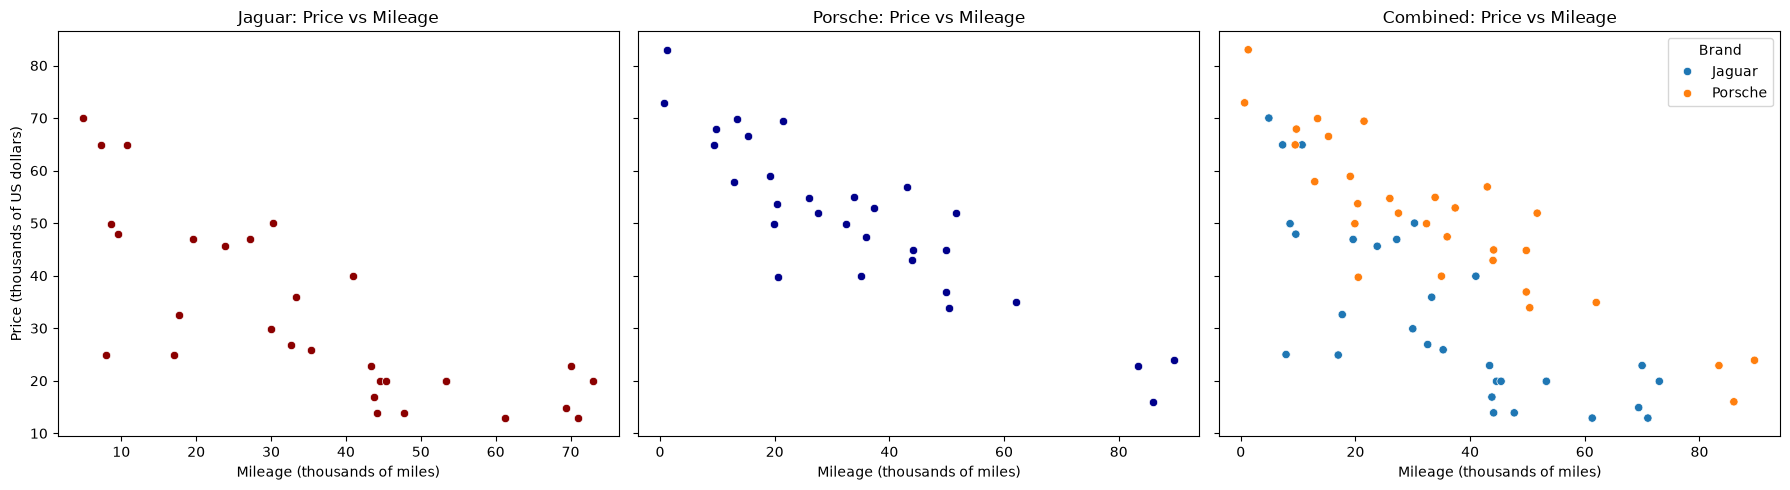

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.scatterplot(data=j_df, x="Mileage", y="Price", ax=axes[0], color="darkred")
axes[0].set_title("Jaguar: Price vs Mileage")
axes[0].set_xlabel("Mileage (thousands of miles)")
axes[0].set_ylabel("Price (thousands of US dollars)")

sns.scatterplot(data=p_df, x="Mileage", y="Price", ax=axes[1], color="darkblue")
axes[1].set_title("Porsche: Price vs Mileage")
axes[1].set_xlabel("Mileage (thousands of miles)")
axes[1].set_ylabel("Price (thousands of US dollars)")

sns.scatterplot(data=df, x="Mileage", y="Price", hue="Brand", ax=axes[2])
axes[2].set_title("Combined: Price vs Mileage")
axes[2].set_xlabel("Mileage (thousands of miles)")
axes[2].set_ylabel("Price (thousands of US dollars)")

plt.tight_layout()

### 4.3 Age vs Price Scatterplots

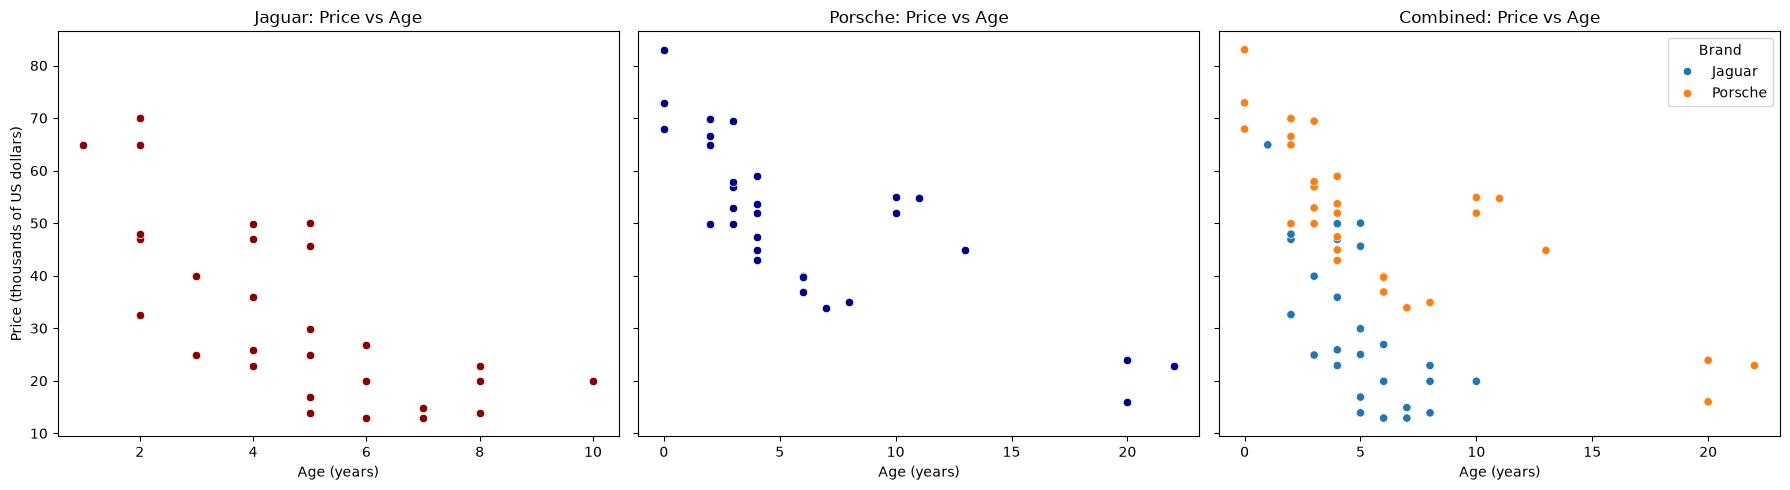

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.scatterplot(data=j_df, x="Age", y="Price", ax=axes[0], color="darkred")
axes[0].set_title("Jaguar: Price vs Age")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Price (thousands of US dollars)")

sns.scatterplot(data=p_df, x="Age", y="Price", ax=axes[1], color="darkblue")
axes[1].set_title("Porsche: Price vs Age")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Price (thousands of US dollars)")

sns.scatterplot(data=df, x="Age", y="Price", hue="Brand", ax=axes[2])
axes[2].set_title("Combined: Price vs Age")
axes[2].set_xlabel("Age (years)")
axes[2].set_ylabel("Price (thousands of US dollars)")

plt.tight_layout()

There is a weak negative correlation between age and price. As vehicle age increases, the price tends to decrease.

### 5.1 Simple Regression Model Setup

We will fit simple linear regression models to quantify the relationship between the predictor variables and the response variable. This helps us estimate the best-fitting linear relationship between price and each explanatory variable.

#### Y = Price and X = Age Models

In [18]:
j_corr = smf.ols(formula="Price ~ Age", data=j_df).fit()
print(j_corr.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.506
Model:                            OLS   Adj. R-squared:                  0.488
Method:                 Least Squares   F-statistic:                     28.67
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.05e-05
Time:                        13:02:03   Log-Likelihood:                -116.12
No. Observations:                  30   AIC:                             236.2
Df Residuals:                      28   BIC:                             239.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     56.9884      5.164     11.035      0.0

In [19]:
p_corr = smf.ols(formula="Price ~ Age", data=p_df).fit()
print(p_corr.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.611
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                     44.04
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           3.36e-07
Time:                        13:02:03   Log-Likelihood:                -110.19
No. Observations:                  30   AIC:                             224.4
Df Residuals:                      28   BIC:                             227.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     63.3750      2.643     23.982      0.0

#### Y = Price and X = Mileage Models

In [20]:
p_corr = smf.ols(formula="Price ~ Mileage", data=p_df).fit()
print(p_corr.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.787
Method:                 Least Squares   F-statistic:                     108.3
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           3.98e-11
Time:                        13:02:03   Log-Likelihood:                -100.63
No. Observations:                  30   AIC:                             205.3
Df Residuals:                      28   BIC:                             208.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     71.0905      2.370     29.998      0.0

In [21]:
j_corr = smf.ols(formula="Price ~ Mileage", data=j_df).fit()
print(j_corr.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.590
Model:                            OLS   Adj. R-squared:                  0.576
Method:                 Least Squares   F-statistic:                     40.36
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           7.11e-07
Time:                        13:02:03   Log-Likelihood:                -113.31
No. Observations:                  30   AIC:                             230.6
Df Residuals:                      28   BIC:                             233.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     54.2275      4.035     13.441      0.0

<Axes: xlabel='Age', ylabel='Price'>

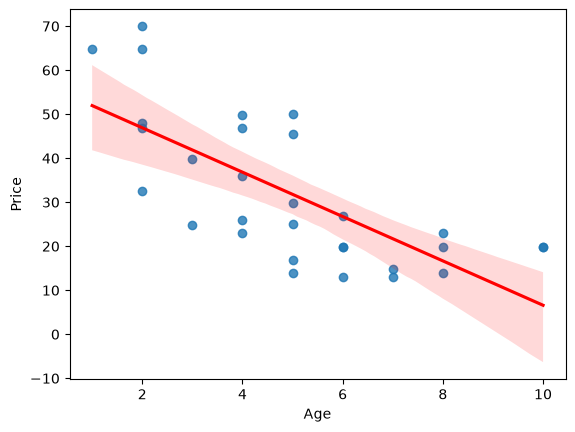

In [22]:
sns.regplot(x="Age", y="Price", data=j_df, line_kws={"color": "red"})

<Axes: xlabel='Age', ylabel='Price'>

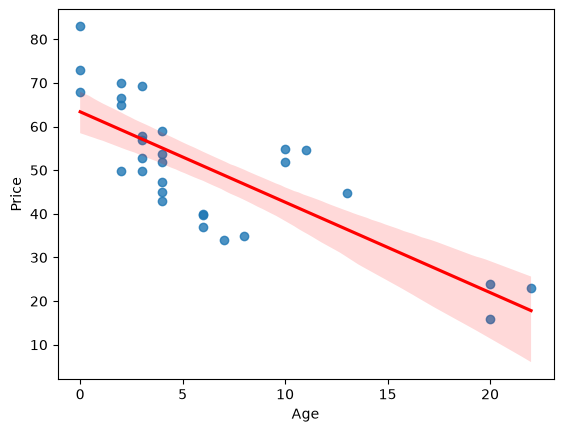

In [23]:
sns.regplot(x="Age", y="Price", data=p_df, line_kws={"color": "red"})

### 5.2 Age Model Results

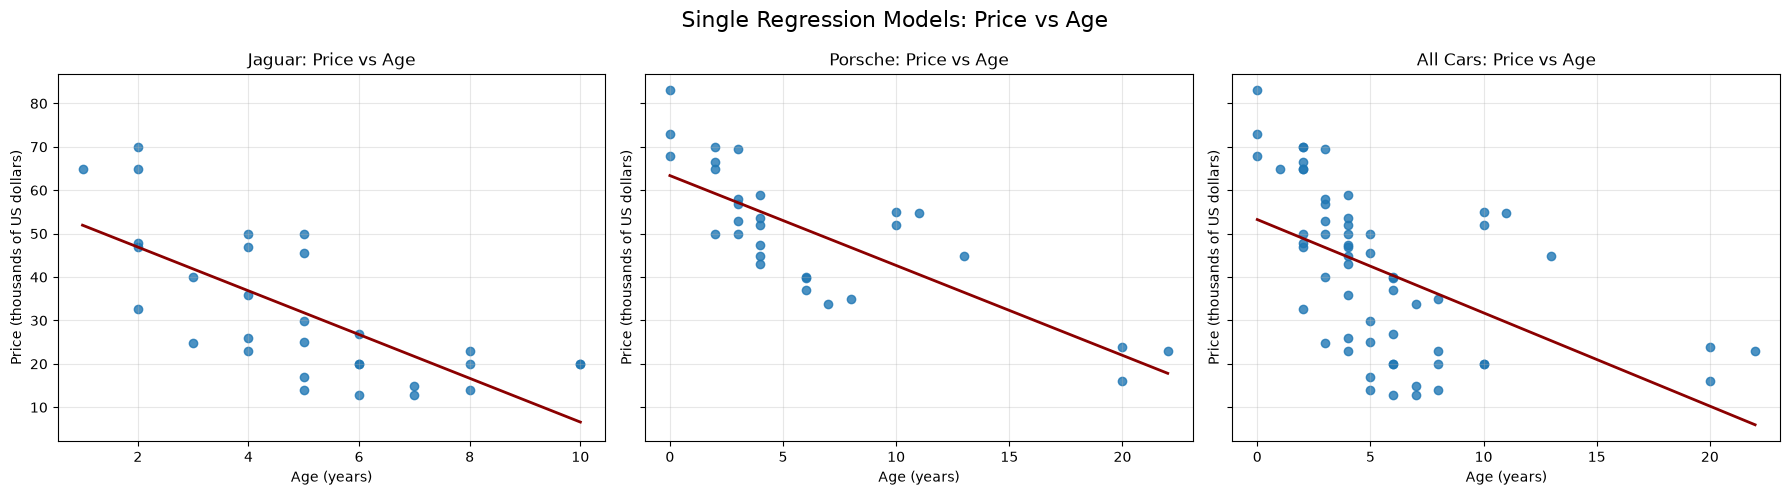

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle("Single Regression Models: Price vs Age", fontsize=16)

for ax, data, label in [
    (axes[0], j_df, "Jaguar"),
    (axes[1], p_df, "Porsche"),
    (axes[2], df, "All Cars")
]:
    ax.scatter(data["Age"], data["Price"], alpha=0.8, color="tab:blue")
    model = smf.ols(formula="Price ~ Age", data=data).fit()
    x_vals = np.linspace(data["Age"].min(), data["Age"].max(), 200)
    y_pred = model.params["Intercept"] + model.params["Age"] * x_vals
    ax.plot(x_vals, y_pred, color="darkred", linewidth=2)
    ax.set_title(f"{label}: Price vs Age")
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Price (thousands of US dollars)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()


### 5.3 Mileage Model Results

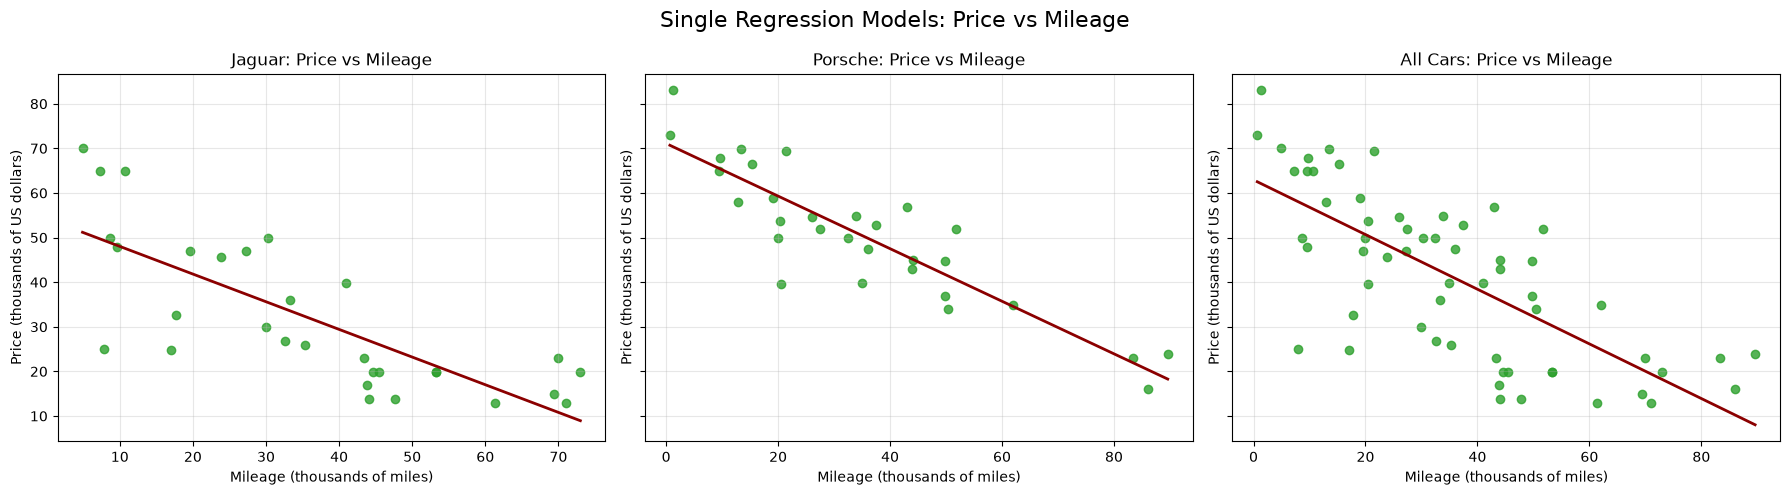

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
fig.suptitle("Single Regression Models: Price vs Mileage", fontsize=16)

for ax, data, label in [
    (axes[0], j_df, "Jaguar"),
    (axes[1], p_df, "Porsche"),
    (axes[2], df, "All Cars")
]:
    ax.scatter(data["Mileage"], data["Price"], alpha=0.8, color="tab:green")
    model = smf.ols(formula="Price ~ Mileage", data=data).fit()
    x_vals = np.linspace(data["Mileage"].min(), data["Mileage"].max(), 200)
    y_pred = model.params["Intercept"] + model.params["Mileage"] * x_vals
    ax.plot(x_vals, y_pred, color="darkred", linewidth=2)
    ax.set_title(f"{label}: Price vs Mileage")
    ax.set_xlabel("Mileage (thousands of miles)")
    ax.set_ylabel("Price (thousands of US dollars)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()


## 6. Multiple Regression Analysis

In [26]:
results = smf.ols(formula="Price ~ Age + Mileage", data=j_df).fit()
print(results.summary())

intercept = results.params["Intercept"]
age_coef = results.params["Age"]
mileage_coef = results.params["Mileage"]

print(f"\nJaguar model coefficients: Intercept={intercept:.2f}, Age Coef={age_coef:.2f}, Mileage Coef={mileage_coef:.2f}")
print(f"Price = {intercept:.2f} + {age_coef:.2f}*(Age) + {mileage_coef:.2f}*(Mileage)")

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.623
Model:                            OLS   Adj. R-squared:                  0.596
Method:                 Least Squares   F-statistic:                     22.35
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.88e-06
Time:                        13:02:04   Log-Likelihood:                -112.05
No. Observations:                  30   AIC:                             230.1
Df Residuals:                      27   BIC:                             234.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.8865      4.602     12.580      0.0

In [27]:
results = smf.ols(formula="Price ~ Age + Mileage", data=p_df).fit()
print(results.summary())

intercept = results.params["Intercept"]
age_coef = results.params["Age"]
mileage_coef = results.params["Mileage"]

print(f"\nPorche model coefficients: Intercept={intercept:.2f}, Age Coef={age_coef:.2f}, Mileage Coef={mileage_coef:.2f}")
print(f"Price = {intercept:.2f} + {age_coef:.2f}*(Age) + {mileage_coef:.2f}*(Mileage)")

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.780
Method:                 Least Squares   F-statistic:                     52.39
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           5.07e-10
Time:                        13:02:04   Log-Likelihood:                -100.59
No. Observations:                  30   AIC:                             207.2
Df Residuals:                      27   BIC:                             211.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.9192      2.484     28.556      0.0

In [28]:
results = smf.ols(formula="Price ~ Age + Mileage", data=df).fit()
print(results.summary())

intercept = results.params["Intercept"]
age_coef = results.params["Age"]
mileage_coef = results.params["Mileage"]

print(f"\nAll cars model coefficients: Intercept={intercept:.2f}, Age Coef={age_coef:.2f}, Mileage Coef={mileage_coef:.2f}")
print(f"Price = {intercept:.2f} + {age_coef:.2f}*(Age) + {mileage_coef:.2f}*(Mileage)")

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.533
Model:                            OLS   Adj. R-squared:                  0.517
Method:                 Least Squares   F-statistic:                     32.54
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           3.74e-10
Time:                        13:02:04   Log-Likelihood:                -237.11
No. Observations:                  60   AIC:                             480.2
Df Residuals:                      57   BIC:                             486.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     62.9497      3.176     19.820      0.0

In [29]:
results = smf.ols(formula="Price ~ Age + Mileage + C(Brand)", data=df).fit()
print(results.summary())

intercept = results.params["Intercept"]
age_coef = results.params["Age"]
mileage_coef = results.params["Mileage"]

print(f"\nAll cars (with brand) model coefficients: Intercept={intercept:.2f}, Age Coef={age_coef:.2f}, Mileage Coef={mileage_coef:.2f}")
print(f"Price = {intercept:.2f} + {age_coef:.2f}*(Age) + {mileage_coef:.2f}*(Mileage)")

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     61.30
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.08e-17
Time:                        13:02:04   Log-Likelihood:                -216.31
No. Observations:                  60   AIC:                             440.6
Df Residuals:                      56   BIC:                             449.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              53.3616    

In [30]:
results.params

Intercept              53.361588
C(Brand)[T.Porsche]    18.403039
Age                    -0.318108
Mileage                -0.552177
dtype: float64

This is a 3D Regression model of my best model from above, Price as the response variable, the Age and Mileage as predictor variables, for Porsche cars only, because it has the highest R-squared among the three options.

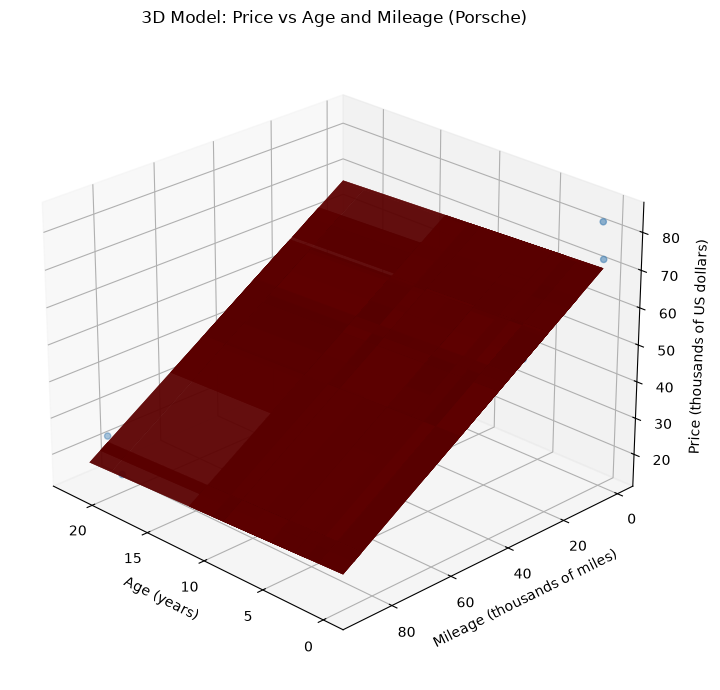

In [31]:
results = smf.ols(formula="Price ~ Age + Mileage", data=p_df).fit()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(p_df["Age"], p_df["Mileage"], p_df["Price"], c="steelblue", alpha=0.8)

x_plane, y_plane = np.meshgrid(p_df["Age"], p_df["Mileage"])
z_plane = (
    results.params["Intercept"]
    + results.params["Age"] * x_plane
    + results.params["Mileage"] * y_plane
)
ax.plot_surface(x_plane, y_plane, z_plane, alpha=0.5, color="darkred")
ax.view_init(elev=25, azim=135)
ax.set_title("3D Model: Price vs Age and Mileage (Porsche)")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Mileage (thousands of miles)")
ax.set_zlabel("Price (thousands of US dollars)")
plt.tight_layout()


### 3D_MODEL

### PREDICT_PORSCHE


In [32]:
AGE_YEARS = 10
MILEAGE_MILES = 55000
MILEAGE_THOUSANDS = MILEAGE_MILES / 1000

porsche_model = smf.ols(formula="Price ~ Age + Mileage", data=p_df).fit()

porsche_intercept = porsche_model.params["Intercept"]
porsche_age_coef = porsche_model.params["Age"]
porsche_mileage_coef = porsche_model.params["Mileage"]

porsche_predicted_thousands = (
    porsche_intercept
    + porsche_age_coef * AGE_YEARS
    + porsche_mileage_coef * MILEAGE_THOUSANDS
)
porsche_predicted_usd = porsche_predicted_thousands * 1000

print(f"Porsche prediction for age={AGE_YEARS} years and mileage={MILEAGE_MILES:,} miles:")
print(f"Predicted price = ${porsche_predicted_usd:,.0f} USD")
print(f"Equivalent model output = {porsche_predicted_thousands:,.2f} thousand USD")


Porsche prediction for age=10 years and mileage=55,000 miles:
Predicted price = $38,743 USD
Equivalent model output = 38.74 thousand USD


### PREDICT_JAGUAR


In [33]:
jaguar_model = smf.ols(formula="Price ~ Age + Mileage", data=j_df).fit()

jaguar_intercept = jaguar_model.params["Intercept"]
jaguar_age_coef = jaguar_model.params["Age"]
jaguar_mileage_coef = jaguar_model.params["Mileage"]

jaguar_predicted_thousands = (
    jaguar_intercept
    + jaguar_age_coef * AGE_YEARS
    + jaguar_mileage_coef * MILEAGE_THOUSANDS
)
jaguar_predicted_usd = jaguar_predicted_thousands * 1000

print(f"Jaguar prediction for age={AGE_YEARS} years and mileage={MILEAGE_MILES:,} miles:")
print(f"Predicted price = ${jaguar_predicted_usd:,.0f} USD")
print(f"Equivalent model output = {jaguar_predicted_thousands:,.2f} thousand USD")


Jaguar prediction for age=10 years and mileage=55,000 miles:
Predicted price = $13,276 USD
Equivalent model output = 13.28 thousand USD


### PREDICT_ALL


In [34]:
all_cars_model = smf.ols(formula="Price ~ Age + Mileage", data=df).fit()

all_cars_intercept = all_cars_model.params["Intercept"]
all_cars_age_coef = all_cars_model.params["Age"]
all_cars_mileage_coef = all_cars_model.params["Mileage"]

all_cars_predicted_thousands = (
    all_cars_intercept
    + all_cars_age_coef * AGE_YEARS
    + all_cars_mileage_coef * MILEAGE_THOUSANDS
)
all_cars_predicted_usd = all_cars_predicted_thousands * 1000

print(f"Overall sports car prediction for age={AGE_YEARS} years and mileage={MILEAGE_MILES:,} miles:")
print(f"Predicted price = ${all_cars_predicted_usd:,.0f} USD")
print(f"Equivalent model output = {all_cars_predicted_thousands:,.2f} thousand USD")


Overall sports car prediction for age=10 years and mileage=55,000 miles:
Predicted price = $29,901 USD
Equivalent model output = 29.90 thousand USD


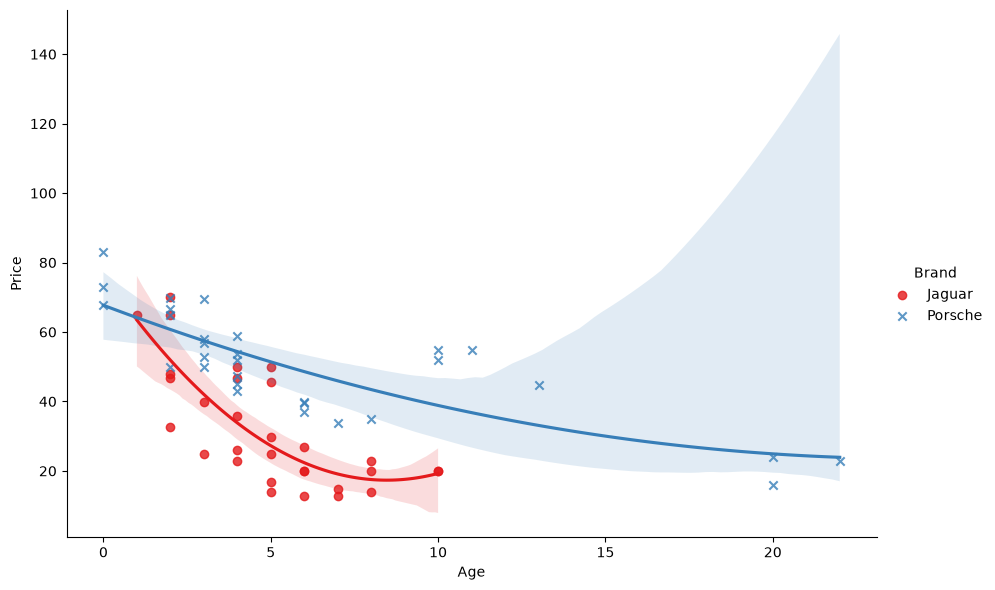

In [35]:
sns.lmplot(x="Age", y="Price", hue="Brand", data=df, markers=["o", "x"], palette="Set1", height=6, aspect=1.5, order=2)

## Q1

Is mileage or age or both factors more strongly correlated to the value of a Porsche?  Of a Jaguar? Of 
all the sportscars combined?

Both milage and age are strongly corrolated to the value of a value of the cars. But it is most strongly correlated with Porche cards, then combined, then a Jaguar.

## Q2 

What is the predictive equation from your best model(s) for Porsches? For Jaguars? For all the cars 
combined? Write your equations in terms of years, miles, and US dollars, rounding to 2 decimal values, 
keeping in mind the units for the models.  If two models are equally as strong, provide both equations. 

The predictive equation from my best Porche model: Price = 70.92 + -0.13*(Age) + -0.56*(Mileage)
The predictive equation from my best Jaguar model: Price = 57.89 + -2.04*(Age) + -0.44*(Mileage)
The predictive equation from my best all cars model: Price = 62.95 + 0.52*(Age) + -0.69*(Mileage)


## Q3

Summarize your predictions for the prices of a 10-year-old Porsche, a Jaguar, and a general sports car 
with 55,000 miles according to your multiple regression model equations to the nearest US dollar. 

10-year-old Porsche prediction with 55,000 miles: $38,743 USD
10-year-old Jaguar prediction with 55,000 miles: $13,276 USD
10-year-old general sports car prediction with 55,000 miles: $29,901 USD


## Q4

How accurate and appropriate is the combined model with all the cars for Porsches? Jaguars? Provide 
reasoning for your answer. 

The combined model is heavily influenced by the Porches' data because when the model formula=Price ~ Age + Mileage, the R squared for Jaguars is 0.623, for Porche it is 0.795, and for all cars it is 0.533 (when the Branch is a 3rd predictor variable, then it is 0.767).